# 4. Noise Models and Image Restoration

Practice for week 4: what common noise models look like in the histogram of a flat patch, the variance of
uniform noise, inverse filtering vs the Wiener filter for blur plus noise, and the prediction error of a
piecewise-constant image with and without noise.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

def make_image(n=256):
    y, x = np.mgrid[:n, :n] / n
    img = 0.25 + 0.4 * x + 0.1 * np.sin(6 * np.pi * y)
    img[(x - 0.3) ** 2 + (y - 0.35) ** 2 < 0.04] = 0.9
    img[(x > 0.55) & (x < 0.9) & (y > 0.55) & (y < 0.85)] = 0.15
    s = (y > 0.7) & (x < 0.45)
    img[s] = 0.5 + 0.3 * np.sign(np.sin(2 * np.pi * 40 * x[s]))
    return img.clip(0, 1)

def psnr(a, b):
    return 10 * np.log10(1 / np.mean((a - b) ** 2))

img = make_image()

## 4.1 Noise models

A flat gray patch makes the noise distribution visible directly in the histogram. Uniform noise on
`[a, b]` has variance `(b − a)² / 12`.

uniform noise variance: measured 0.01325, formula 0.01333


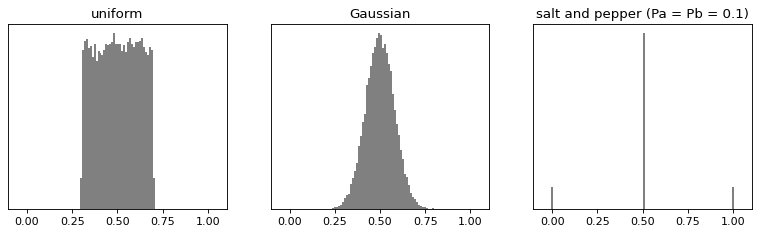

In [2]:
flat = np.full((200, 200), 0.5)
a, b = -0.2, 0.2
uni = flat + rng.uniform(a, b, flat.shape)
gau = flat + rng.normal(0, 0.08, flat.shape)
sp = flat.copy(); r = rng.random(flat.shape); sp[r < 0.1] = 0.0; sp[r > 0.9] = 1.0
print(f"uniform noise variance: measured {np.var(uni - flat):.5f}, formula {(b - a) ** 2 / 12:.5f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, u, t in zip(axes, [uni, gau, sp], ["uniform", "Gaussian", "salt and pepper (Pa = Pb = 0.1)"]):
    ax.hist(u.ravel(), 100, range=(-0.05, 1.05), color="gray"); ax.set_title(t); ax.set_yticks([])
plt.show()

## 4.2 Blur plus noise: inverse filter vs Wiener filter

Degradation model: `g = h * f + n` with horizontal motion blur `h` (9 px) and Gaussian noise. In the Fourier
domain `G = H F + N`. The inverse filter `G / H` divides by near-zero values of `H` and blows the noise up.
The Wiener filter `H* / (|H|² + K) · G` minimizes the expected squared error; `K` is the noise-to-signal
ratio and is picked here by a small search.

blurred + noise 17.5 dB | inverse filter 8.4 dB | Wiener (K = 1e-02) 24.9 dB


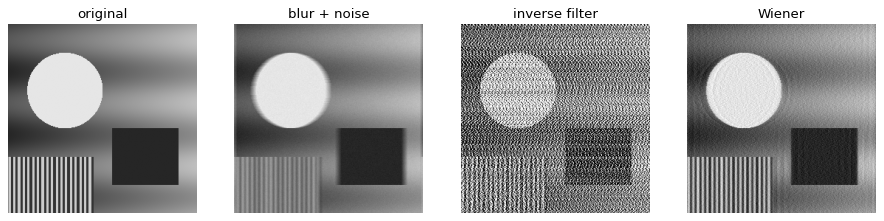

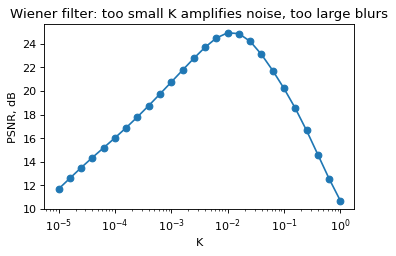

In [3]:
psf = np.zeros(img.shape); psf[0, :9] = 1 / 9; psf = np.roll(psf, -4, axis=1)
Hf = np.fft.fft2(psf)
blurred = np.fft.ifft2(np.fft.fft2(img) * Hf).real
g = blurred + rng.normal(0, 0.01, img.shape)
G = np.fft.fft2(g)

inverse = np.fft.ifft2(G / np.where(np.abs(Hf) < 1e-3, 1e-3, Hf)).real
wiener = lambda K: np.fft.ifft2(np.conj(Hf) / (np.abs(Hf) ** 2 + K) * G).real
Ks = np.logspace(-5, 0, 26)
scores = [psnr(wiener(K).clip(0, 1), img) for K in Ks]
best = Ks[int(np.argmax(scores))]
print(f"blurred + noise {psnr(g, img):.1f} dB | inverse filter {psnr(inverse.clip(0, 1), img):.1f} dB | "
      f"Wiener (K = {best:.0e}) {max(scores):.1f} dB")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, u, t in zip(axes, [img, g, inverse, wiener(best)], ["original", "blur + noise", "inverse filter", "Wiener"]):
    ax.imshow(u.clip(0, 1), cmap="gray", vmin=0, vmax=1); ax.set_title(t); ax.axis("off")
plt.show()
plt.figure(figsize=(5, 3)); plt.semilogx(Ks, scores, "o-"); plt.xlabel("K"); plt.ylabel("PSNR, dB")
plt.title("Wiener filter: too small K amplifies noise, too large blurs"); plt.show()

Enhancement (3.x) only tries to make the image look better. Restoration uses a model of the degradation,
which is why the Wiener filter can undo motion blur that no sharpening filter would remove.

## 4.3 Prediction error of a piecewise-constant image

For a piecewise-constant image the left-neighbour prediction error is zero everywhere except at edges,
where it equals the jump. Add Gaussian noise and each of those values becomes a Gaussian mode: one big mode
at 0 and small ones at ± each jump.

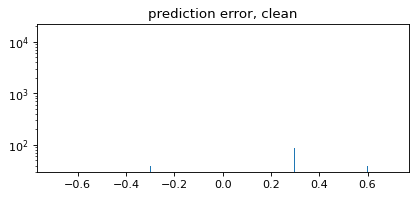

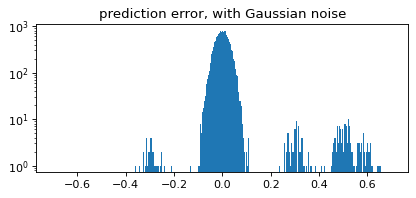

In [4]:
pc = np.zeros((128, 128)); pc[:, 40:] = 0.3; pc[:, 90:] = 0.8; pc[60:100, 10:60] = 0.6
for u, t in [(pc, "clean"), (pc + rng.normal(0, 0.02, pc.shape), "with Gaussian noise")]:
    e = (u[:, 1:] - u[:, :-1]).ravel()
    plt.figure(figsize=(6, 2.4)); plt.hist(e, 400, range=(-0.7, 0.7), color="tab:blue", log=True)
    plt.title(f"prediction error, {t}"); plt.show()